# Google Local Research Team
Complete corrected analysis for Tasks 1 to 3. Run all cells from the repository root. Business strategy and ethics are in the report. Raw data is preserved; private derived outputs are excluded from Git.

In [12]:
from pathlib import Path
import pandas as pd
from analysis import main
summary = main()
OUT = Path("outputs")

Cleaning 17,706 text reviews
Scoring original review text with VADER
{
  "datasets": [
    {
      "dataset": "Places",
      "rows": 22476,
      "columns": 7,
      "exact_duplicates": 0,
      "missing_cells": 25025
    },
    {
      "dataset": "Reviews",
      "rows": 21767,
      "columns": 7,
      "exact_duplicates": 0,
      "missing_cells": 4301
    },
    {
      "dataset": "Users",
      "rows": 21858,
      "columns": 6,
      "exact_duplicates": 0,
      "missing_cells": 30067
    }
  ],
  "reviews_without_place": 14622,
  "reviews_without_user": 0,
  "invalid_dates": 0,
  "reviews_with_text": 17706,
  "reviews_without_text": 4061,
  "it_specialists": 5,
  "places_over_three": 4,
  "five_star_text_reviews": 11114,
  "spelling_replacements": 104,
  "distinct_spelling_changes": 9,
  "expanded_reviews": 5251,
  "rating_agreement_percent": 77.93,
  "places_with_at_least_ten_text_reviews": 0,
  "runtime_seconds": 16.22,
  "source_sha256": {
    "Place.csv": "204d8552677314eac2

## Task 1 Data quality and preparation
Identifiers are strings. Primary keys, foreign keys, ratings and dates are checked. Missing optional values are retained. Text correction is separate from the raw VADER input.

In [13]:
display(pd.read_csv(OUT/"data_quality.csv"))
display(pd.read_csv(OUT/"missing_values.csv"))
display(pd.read_csv(OUT/"spelling_changes.csv").head(15))

,dataset,rows,columns,exact_duplicates,missing_cells
0,Places,22476,7,0,25025
1,Reviews,21767,7,0,4301
2,Users,21858,6,0,30067


,dataset,column,missing
0,Places,gPlusPlaceId,0
1,Places,name,0
2,Places,price,15784
3,Places,address,0
4,Places,hours,7876
5,Places,phone,1365
6,Places,closed,0
7,Reviews,gPlusPlaceId,0
8,Reviews,gPlusUserId,0
9,Reviews,rating,0


,original,replacement,occurrences
0,recomend,recommend,28
1,definately,definitely,17
2,recieved,received,16
3,recieve,receive,8
4,awsome,awesome,8
5,pleasent,pleasant,8
6,experiance,experience,7
7,resturant,restaurant,6
8,thier,their,6


## Task 1 Text preparation examples

In [14]:
from pprint import pformat
from analysis import load_table, expand_contractions, TOKENIZER
places = load_table("Place.csv")
reviews = load_table("reviews.csv")
users = load_table("users.csv")
text = pd.read_json("data/processed/review_text.jsonl", lines=True,
                    dtype={"gPlusPlaceId": str, "gPlusUserId": str})
examples = text[(text.normalizedText.str.len() < 90) &
                (text.normalizedText != text.expandedText)].head(2)
for value in examples.normalizedText:
    expanded = expand_contractions(value)
    print("Original:", value)
    print("Expanded:", expanded)
    print("Tokens:", pformat(TOKENIZER.tokenize(expanded), width=100), "\n")

Original: It's all about Tuesdays and Thursdays- $1 tacos and 35 cent wings!
Expanded: it is all about Tuesdays and Thursdays- $1 tacos and 35 cent wings!
Tokens: ['it',
 'is',
 'all',
 'about',
 'Tuesdays',
 'and',
 'Thursdays-',
 '$',
 '1',
 'tacos',
 'and',
 '35',
 'cent',
 'wings',
 '!'] 

Original: Best fried rice I've ever had! Love the sesame chicken as well. Quick take out!
Expanded: Best fried rice I have ever had! Love the sesame chicken as well. Quick take out!
Tokens: ['Best',
 'fried',
 'rice',
 'I',
 'have',
 'ever',
 'had',
 '!',
 'Love',
 'the',
 'sesame',
 'chicken',
 'as',
 'well.',
 'Quick',
 'take',
 'out',
 '!'] 



## Task 2a Places with more than three reviews

In [15]:
review_counts = reviews.groupby("gPlusPlaceId").size().reset_index(name="review_count")
more_than_three = review_counts[review_counts.review_count > 3]
display(more_than_three.sort_values("gPlusPlaceId"))

,gPlusPlaceId,review_count
1585,100515652515321866651,4
5226,102250986789579477120,4
6631,103029351909058756043,4
10115,105590614995402411627,4


## Task 2b Closed and operating places

In [16]:
status_counts = places["closed"].value_counts(dropna=False)
print("Operating:", status_counts.get("False", 0))
print("Permanently closed:", status_counts.get("True", 0))
print("Total places:", len(places))

Operating: 21720
Permanently closed: 756
Total places: 22476


## Task 2c Top twenty phrases

In [17]:
import re
from collections import Counter
trigrams = Counter()
for value in text.loc[text.rating == 5, "correctedText"]:
    words = re.findall(r"[^\W\d_]+(?:'[^\W\d_]+)?", value.lower())
    trigrams.update(" ".join(words[i:i+3]) for i in range(len(words)-2))
top_twenty = pd.DataFrame(
    sorted(trigrams.items(), key=lambda item: (-item[1], item[0]))[:20],
    columns=["phrase", "frequency"])
display(top_twenty)

,phrase,frequency
0,i have been,584
1,i highly recommend,369
2,one of the,363
3,i have ever,278
4,i would recommend,263
5,if you are,256
6,i have had,235
7,is the best,222
8,would highly recommend,217
9,the staff is,212


## Task 2d IT Specialist subset
Identifiers abbreviated for public evidence; the complete subset is saved locally.

In [18]:
specialists = users[users["jobs"] == "IT Specialist"]
view = specialists[["gPlusUserId", "jobs"]].copy()
view["gPlusUserId"] = view.gPlusUserId.str[:4] + "..." + view.gPlusUserId.str[-4:]
print("Matching users:", len(specialists))
display(view)

Matching users: 5


,gPlusUserId,jobs
71,1000...9266,IT Specialist
4403,1002...6638,IT Specialist
9848,1005...0587,IT Specialist
13968,1007...4882,IT Specialist
17023,1009...8529,IT Specialist


## Task 2e Most reviewed places and ties

In [19]:
maximum = review_counts.review_count.max()
winners = review_counts[review_counts.review_count == maximum]
winners = winners.merge(places[["gPlusPlaceId", "name"]],
                        on="gPlusPlaceId", how="left", validate="one_to_one")
winners["name"] = winners["name"].fillna("Unavailable in supplied Places")
display(winners)

,gPlusPlaceId,review_count,name
0,100515652515321866651,4,Unavailable in supplied Places
1,102250986789579477120,4,Scott Clark Honda
2,103029351909058756043,4,Unavailable in supplied Places
3,105590614995402411627,4,Unavailable in supplied Places


## Task 3 Sentiment counts

In [20]:
from nltk.sentiment import SentimentIntensityAnalyzer
from analysis import sentiment_label
sia = SentimentIntensityAnalyzer()
text["compound"] = text.normalizedText.map(lambda value: sia.polarity_scores(value)["compound"])
text["sentiment"] = text.compound.map(sentiment_label)
sentiment_counts = text.sentiment.value_counts().reindex(["Positive", "Neutral", "Negative"])
print("Reviews with text:", len(text))
print("Reviews excluded because text is missing:", len(reviews) - len(text))
display(sentiment_counts.rename_axis("sentiment").reset_index(name="reviews"))

Reviews with text: 17706
Reviews excluded because text is missing: 4061


,sentiment,reviews
0,Positive,13498
1,Neutral,1995
2,Negative,2213


## Task 3 Rating comparison

In [21]:
text["ratingSentiment"] = text.rating.map(
    lambda value: "Positive" if value >= 4 else "Negative" if value <= 2 else "Neutral")
display(pd.crosstab(text.ratingSentiment, text.sentiment))
agreement = (text.ratingSentiment == text.sentiment).mean() * 100
print(f"Rating agreement: {agreement:.2f}% (proxy, not verified accuracy)")

sentiment,Negative,Neutral,Positive
ratingSentiment,,,
Negative,1421,308,760
Neutral,302,314,674
Positive,490,1373,12064


Rating agreement: 77.93% (proxy, not verified accuracy)


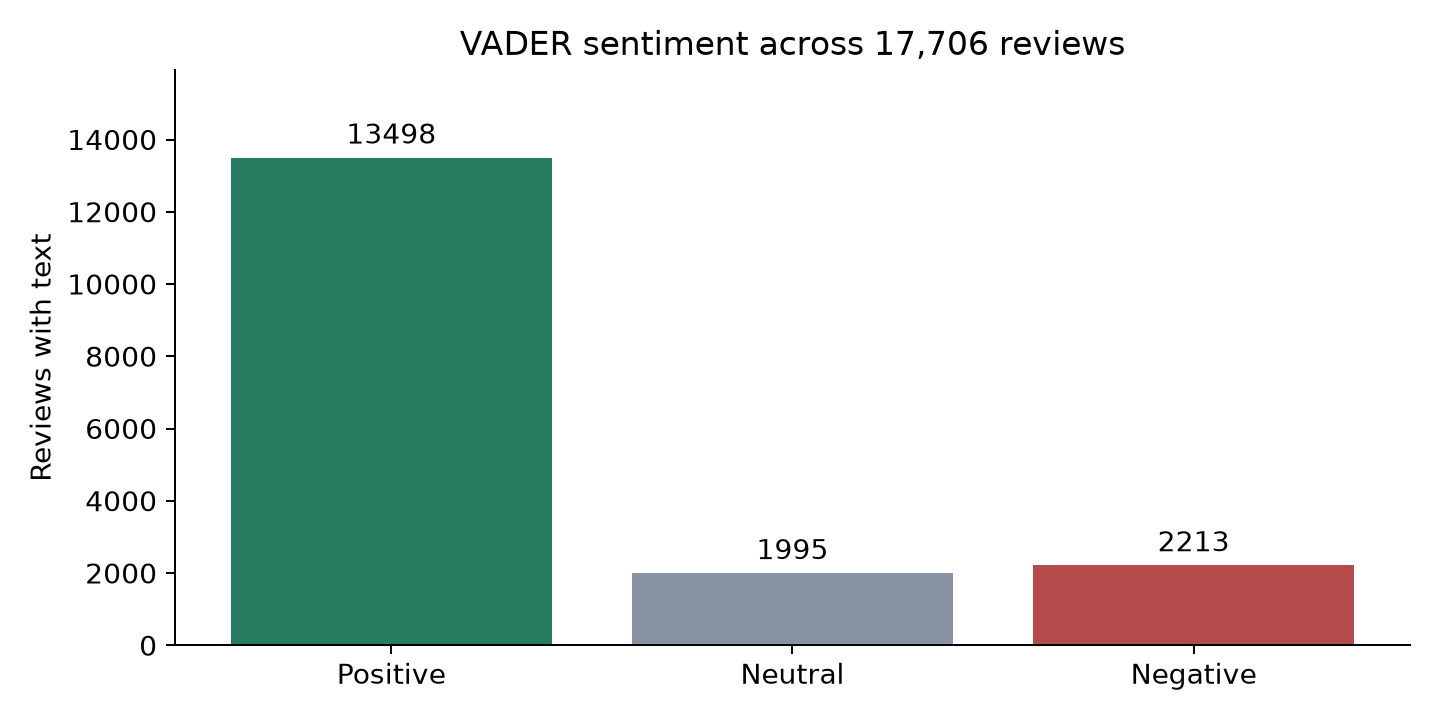

In [22]:
from IPython.display import Image, display
display(Image(filename=str(OUT/"sentiment_distribution.png")))